## Why this project?
I have worked in customer support domain for a telecom company based in the US for few years as an agent and later was promoted to trainer, while handling customers issues as an agent we were taught to identify "Bells of Churn", initially I used to think why do we need to do this?, can't we just simply resolve customer's issues and just live peacefully. 

Later I understood the business point of view, for any business customer churn is the biggest pain point, Customer can leave service because of several reasons like - bad customer experience, bad product, incompetent customer support, unreasonable price of the product and so on. 
Hence as I am learning Data Science let's actually understand, why do customers leave and solve a real life problem using Data Science and Machine Learning.
Goal of this project:
* Perform Exploratory Data Analysis
* Visualize the Data
* Select the correct Machine Learning model
* Evaluate accuracy of the model
* Run Shap to find what actually needs to be done to save customers from churn

### The final goal of this project is not just accuracy, but actionable retention strategies.

Here I am using Telco Customer Dataset from Kaggle

In [1]:

import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 
import sklearn

In [2]:
data = pd.read_csv("Telco-Customer-Churn.csv")

In [3]:
data.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Understanding the data
* CustomerID - Unique identifier for each customer.
* Gender - Male/Female.
* SeniorCitizen - Flag (1 = age ≥ 60, 0 = younger).
* Partner - Whether the customer has a spouse/partner.
* Dependents - Whether the customer has dependents (children, family).
* Tenure - Number of months the customer has stayed with the company.
* PhoneService - Whether the customer has a phone line.
* MultipleLines - Whether the customer has multiple phone lines.
* InternetService - Type of internet service (DSL, Fiber optic, None).
* OnlineSecurity - Whether the customer has online security add‑on.
* OnlineBackup - Whether the customer has online backup add‑on.
* DeviceProtection - Whether the customer has device protection add‑on.
* TechSupport - Whether the customer has tech support add‑on.
* StreamingTV - Whether the customer has streaming TV service.
* StreamingMovies - Whether the customer has streaming movies service
* Contract - Contract type (Month‑to‑month, One year, Two year).
* PaperlessBilling - Whether billing is paperless.
* PaymentMethod - Payment type (Electronic check, Mailed check, Bank transfer, Credit card).
* MonthlyCharges - Amount charged per month.
* TotalCharges - Total amount charged over tenure.
* Churn - Target variable (Yes = customer left, No = customer stayed).

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

# Exploratory Data Analysis

### Finding null values

In [5]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### There are no null values

### For a ML model we need to make sure that all the data is in correct format

In [7]:
data["TotalCharges"] = data["TotalCharges"].replace({" ": "0.0"})

In [8]:
# Converting TotalCharges to float32/ float64
data["TotalCharges"] = data["TotalCharges"].astype(float)

In [9]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Exploring Churn Distribution

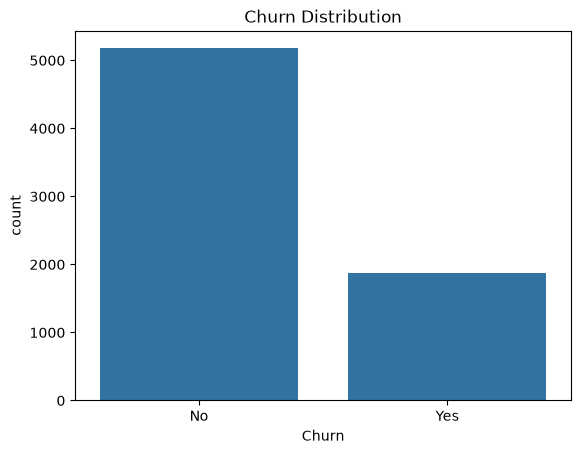

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [10]:
sns.countplot(x = "Churn", data = data)
plt.title("Churn Distribution")
plt.show()
print(data["Churn"].value_counts(normalize=True))

From the above observation we can see that are 73.46% people stayed and around 26.53% people left

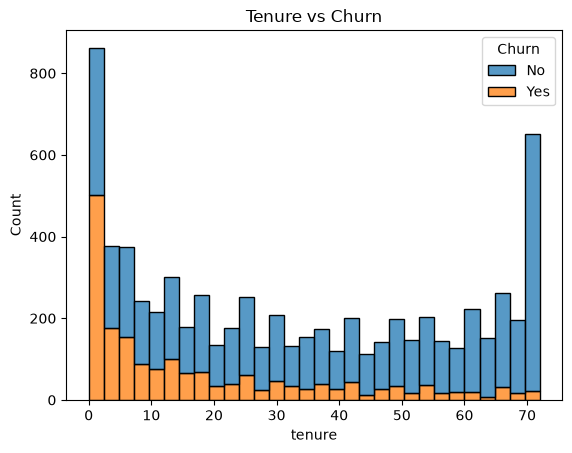

In [11]:
# Finding relationship between tenure and churn
sns.histplot(data = data, x= "tenure", hue = "Churn", multiple = "stack", bins = 30)
plt.title("Tenure vs Churn")
plt.show()

From the above histogram we can see that new customers has a high Churn rate

In [12]:
print(data["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


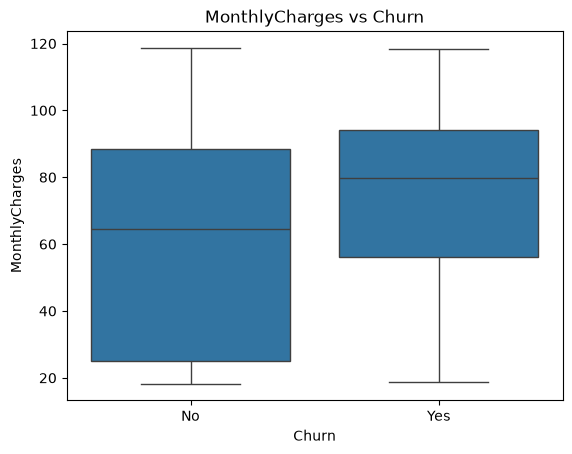

In [13]:
# finding the relationship between Monthly charges and Churn
sns.boxplot(x ="Churn", y = "MonthlyCharges", data = data)
plt.title("MonthlyCharges vs Churn")
plt.show()

Customers with higher monthly charges are significantly more likely to churn compared to those paying lower charges.

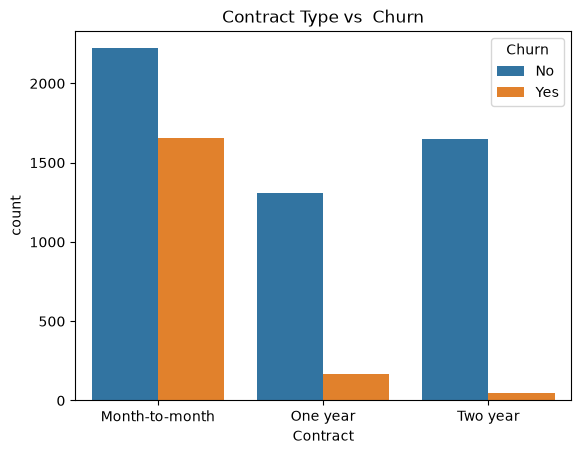

In [14]:
# ContractType vs Churn
sns.countplot(x = "Contract", hue = "Churn", data = data)
plt.title("Contract Type vs  Churn")
plt.show()

Customers with Month to Month contracts tend to leave more

In [15]:
pd.set_option('display.max_columns', None)
data.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No


In [16]:
print(data.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


# Encode Categorical variables

In [18]:
# Categorizig the columns on the basis of the data
binary_cols = [
    "SeniorCitizen", "PhoneService", "PaperlessBilling"
]
nominal_cols = [
    "gender", "Partner", "Dependents", 'MultipleLines',
    'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'Contract', 'PaymentMethod'
]

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

In [19]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


LabelEncoding of Target Column

In [21]:
data["Churn"]  = data["Churn"].replace({"No": 0, "Yes":1})
data["Churn"].astype(float)

0       0.0
1       0.0
2       1.0
3       0.0
4       1.0
       ... 
7038    0.0
7039    0.0
7040    0.0
7041    1.0
7042    0.0
Name: Churn, Length: 7043, dtype: float64

Label Encoding of Nominal column

In [22]:
from sklearn.preprocessing import LabelEncoder

label_encoders = {}
for col in nominal_cols:
    le = LabelEncoder()
    label_encoders[col] = le
    data[col] = le.fit_transform(data[col])

In [23]:
data[nominal_cols].head(3)

,gender,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaymentMethod
0,0,1,0,1,0,0,2,0,0,0,0,0,2
1,1,0,0,0,0,2,0,2,0,0,0,1,3
2,1,0,0,0,0,2,2,0,0,0,0,0,3


Encoding  Categorical columns

In [24]:
data["PhoneService"] = data["PhoneService"].replace({"No":0, "Yes":1})
data["PaperlessBilling"] = data["PaperlessBilling"].replace({"No":0,"Yes": 1})
data[binary_cols]

,SeniorCitizen,PhoneService,PaperlessBilling
0,0,0,1
1,0,1,0
2,0,1,1
3,0,0,0
4,0,1,1
...,...,...,...
7038,0,1,1
7039,0,1,1
7040,0,0,1
7041,1,1,1


In [25]:
data.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0


## Spliting data in test and train splits

In [30]:
X = data.drop(columns = ["customerID", "Churn"])
y = data["Churn"].astype(float)

In [31]:
print(y.dtype)

float64


In [32]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(X, y, random_state=42, test_size=0.3, stratify= y)

## Model Selection
As we are dealing with Classfication problem (Churn Yes/ No) we can try Logistic regression, Tree based models

In [33]:
from sklearn.linear_model import LogisticRegression

In [34]:
# Standardize the variable for better results
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [35]:
X_train_scaled = scaler.fit_transform(X_train)

In [36]:
X_test_scaled = scaler.transform(X_test)

In [37]:
X_train_scaled

array([[-1.00528781, -0.43814715, -0.96295739, ...,  0.40179108,
         0.50428615, -0.83650447],
       [-1.00528781,  2.28233828, -0.96295739, ...,  0.40179108,
         0.72418915, -0.90774191],
       [-1.00528781, -0.43814715,  1.03846754, ..., -0.53432897,
         0.33729214, -0.9095741 ],
       ...,
       [-1.00528781, -0.43814715,  1.03846754, ...,  0.40179108,
         1.46491504,  2.3582526 ],
       [-1.00528781, -0.43814715,  1.03846754, ..., -0.53432897,
        -1.47318743, -0.79351335],
       [ 0.99474   , -0.43814715, -0.96295739, ...,  1.33791114,
        -1.4649204 , -0.95644773]], shape=(4930, 19))

In [38]:
y_train = y_train.astype(int)
print(y_train.dtype)

int64


In [39]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

In [40]:
# Assigning a Logistic Regression object
lr = LogisticRegression(max_iter=1000)

In [41]:
lr.fit(X_train_smote, y_train_smote)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [42]:
# Predictions
y_pred = lr.predict(X_test_scaled)
y_pred_proba = lr.predict_proba(X_test_scaled)[:, 1]

In [43]:
# Evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [44]:
y_test = y_test.astype(int)

In [45]:
print("Accuracy Score:", accuracy_score(y_test, y_pred))

print("Classification Report:\n",
      classification_report(y_test, y_pred))

print("Confusion Matrix:\n",
      confusion_matrix(y_test, y_pred))

print("ROC-AUC Score:",
      roc_auc_score(y_test, y_pred_proba))

Accuracy Score: 0.7439659252247989
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1552
           1       0.51      0.79      0.62       561

    accuracy                           0.74      2113
   macro avg       0.71      0.76      0.71      2113
weighted avg       0.80      0.74      0.76      2113

Confusion Matrix:
 [[1127  425]
 [ 116  445]]
ROC-AUC Score: 0.8432262666078615


Logistic Regression baseline gave us a good starting point, but the results show it’s plateauing: accuracy around 75–80%, ROC‑AUC ~0.72–0.75, and recall for churners stuck near 0.53. That recall is too low for our business goal that is to catch at‑risk customers.

Using other ML models for better results and performance

In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf = RandomForestClassifier(
    n_estimators = 200,
    max_depth= None,
    random_state = 42
)

In [48]:
rf.fit(X_train_smote, y_train_smote)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [49]:
y_pred_rf = rf.predict(X_test)

y_pred_proba_rf = rf.predict_proba(X_test)[:, 1]

c:\Users\91888\Downloads\Customer_Churn_Prediction_Project\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\91888\Downloads\Customer_Churn_Prediction_Project\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


In [50]:
print("Accuracy score:\n", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("ROC AUC score:\n", roc_auc_score(y_test, rf.predict_proba(X_test)[:,1]))


Accuracy score:
 0.7439659252247989
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1552
           1       0.51      0.79      0.62       561

    accuracy                           0.74      2113
   macro avg       0.71      0.76      0.71      2113
weighted avg       0.80      0.74      0.76      2113

Confusion Matrix:
 [[1127  425]
 [ 116  445]]
ROC AUC score:
 0.6461319532499035


c:\Users\91888\Downloads\Customer_Churn_Prediction_Project\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


In [51]:
print(y_train_smote.value_counts())

Churn
0    3622
1    3622
Name: count, dtype: int64


Random Forest Classifier has performed better in terms of ROC AUC score than LogisticRegression

In [52]:
# Trying XGBoost
%pip install xgboost
from xgboost import XGBClassifier

Note: you may need to restart the kernel to use updated packages.


In [53]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)   

In [54]:
xgb.fit(X_train_smote, y_train_smote)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [55]:
y_pred = xgb.predict(X_test_scaled)

y_pred_proba = xgb.predict_proba(X_test_scaled)[:, 1]

In [56]:
print("Accuracy score:\n", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("ROC AUC score:\n", roc_auc_score(y_test, rf.predict_proba(X_test)[:,1]))

Accuracy score:
 0.77520113582584
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.85      0.85      1552
           1       0.58      0.58      0.58       561

    accuracy                           0.78      2113
   macro avg       0.71      0.71      0.71      2113
weighted avg       0.78      0.78      0.78      2113

Confusion Matrix:
 [[1313  239]
 [ 236  325]]
ROC AUC score:
 0.6461319532499035


c:\Users\91888\Downloads\Customer_Churn_Prediction_Project\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Saving the model

In [81]:
import joblib
import pickle

In [82]:
model_data = {
    "model": xgb,
    "feature_names": X.columns.tolist(),
    "encoders": label_encoders,
    "scaler": scaler,
}

with open("customer_churn_model.pkl", "wb") as f:
    pickle.dump(model_data, f)

Test a customer with the saved model

In [85]:
with open("customer_churn_model.pkl", "rb") as f:
    saved_model_data = pickle.load(f)

if isinstance(saved_model_data, dict):
    loaded_model = saved_model_data["model"]
    loaded_feature_names = saved_model_data["feature_names"]
    loaded_encoders = saved_model_data.get("encoders", label_encoders)
    loaded_scaler = saved_model_data.get("scaler", scaler)
else:
    # Support the existing classifier-only pickle with preprocessing from this run.
    loaded_model = saved_model_data
    loaded_feature_names = X.columns.tolist()
    loaded_encoders = label_encoders
    loaded_scaler = scaler

if loaded_feature_names != X.columns.tolist():
    raise ValueError("The saved model feature names do not match the training data.")

loaded_predictions = loaded_model.predict(X_test_scaled)
print("Loaded model accuracy:", accuracy_score(y_test, loaded_predictions))

### SHAP: understand the model's churn drivers
If SHAP is not installed, run `%pip install shap` once in this notebook. SHAP ranks which features influence predictions; use the results to choose retention ideas to test, not as proof that changing a feature will prevent churn.

c:\Users\91888\Downloads\Customer_Churn_Prediction_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Feature,Mean absolute SHAP
14,Contract,1.102556
4,tenure,0.734648
17,MonthlyCharges,0.626941
16,PaymentMethod,0.341581
18,TotalCharges,0.329826
8,OnlineSecurity,0.289728
11,TechSupport,0.201888
7,InternetService,0.188668
15,PaperlessBilling,0.184001
6,MultipleLines,0.163183


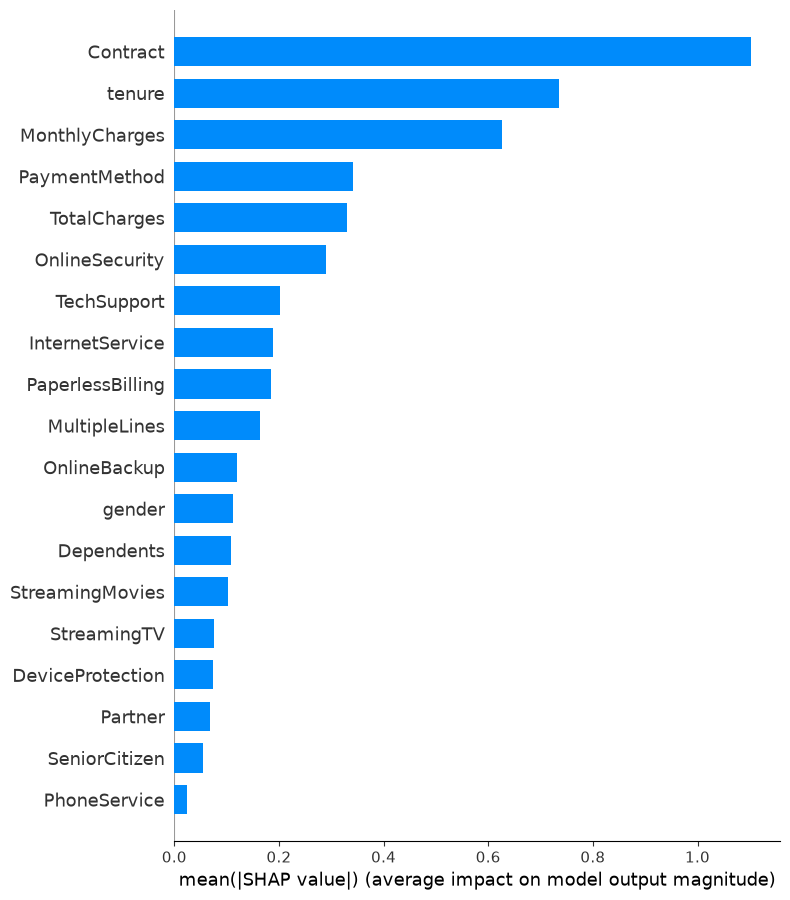

In [88]:
import shap

explainer = shap.TreeExplainer(loaded_model)
shap_values = explainer(X_test_scaled)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean absolute SHAP": np.abs(shap_values.values).mean(axis=0),
}).sort_values("Mean absolute SHAP", ascending=False)

display(importance.head(10))
shap.summary_plot(shap_values.values, X_test_scaled, feature_names=X.columns, plot_type="bar")

Edit the customer values in the code cell below, then run it to predict churn or no churn.

In [89]:
import pickle
import pandas as pd

with open("customer_churn_model.pkl", "rb") as f:
    model_data = pickle.load(f)

customer = {
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 1,
    "PhoneService": "No",
    "MultipleLines": "No phone service",
    "InternetService": "DSL",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 29.85,
    "TotalCharges": 29.85,
}

customer = pd.DataFrame([customer], columns=model_data["feature_names"])
for column, encoder in model_data["encoders"].items():
    customer[column] = encoder.transform(customer[column])
customer["PhoneService"] = customer["PhoneService"].map({"No": 0, "Yes": 1})
customer["PaperlessBilling"] = customer["PaperlessBilling"].map({"No": 0, "Yes": 1})

customer_scaled = model_data["scaler"].transform(customer)
prediction = model_data["model"].predict(customer_scaled)[0]
print("Churn" if prediction == 1 else "No churn")

Churn


### Why did this customer get this prediction?
Positive SHAP values push the prediction toward churn; negative values push it toward no churn. Suggested steps are hypotheses to validate.

In [90]:
customer_shap = explainer(customer_scaled).values[0]
reasons = pd.DataFrame({
    "Feature": model_data["feature_names"],
    "SHAP value": customer_shap,
}).sort_values("SHAP value", ascending=False)

print("Factors pushing toward churn:")
display(reasons.head(3))
print("Factors pushing away from churn:")
display(reasons.tail(3).sort_values("SHAP value"))

retention_ideas = {
    "Contract": "Offer a contract that better fits the customer's needs; test term incentives.",
    "tenure": "Use early-tenure customers to target onboarding and proactive support; tenure itself cannot be changed.",
    "MonthlyCharges": "Review plan fit and billing; test targeted, sustainable offers.",
    "TotalCharges": "Review billing history and explain charges clearly.",
    "PaymentMethod": "Check for payment friction and offer convenient payment options.",
    "OnlineSecurity": "Ask about security needs and explain relevant service options.",
    "TechSupport": "Offer proactive technical support and investigate recurring issues.",
    "InternetService": "Check connection quality and whether the service plan fits.",
    "PhoneService": "Check whether the phone service and plan fit the customer's needs.",
}
print("Retention ideas to test for the strongest churn drivers:")
churn_drivers = reasons[reasons["SHAP value"] > 0].head(3)
for feature in churn_drivers["Feature"]:
    if feature in retention_ideas:
        print("-", retention_ideas[feature])
if churn_drivers.empty:
    print("No features pushed this prediction toward churn.")

Factors pushing toward churn:


,Feature,SHAP value
4,tenure,1.018246
14,Contract,0.847348
5,PhoneService,0.344116


Factors pushing away from churn:


,Feature,SHAP value
7,InternetService,-0.368503
18,TotalCharges,-0.337567
17,MonthlyCharges,-0.333563


Retention ideas to test for the strongest churn drivers:
- Use early-tenure customers to target onboarding and proactive support; tenure itself cannot be changed.
- Offer a contract that better fits the customer's needs; test term incentives.
- Check whether the phone service and plan fit the customer's needs.
